# Assignment 3 — Module 3: Evolutionary and Swarm Optimization

**Student Name:** Arendra Singh Rajput  
**Roll No.:** 2023BTCSE003  
**Enrollment No.:** JLU08391  
**Course:** B.Tech CSE, 4th Year  
**Subject:** Soft Computing Exercise  

---

## Practical 6: Simple Genetic Algorithm Combining Selection, Crossover and Mutation

### Aim
To create a simple Genetic Algorithm by combining selection, crossover, and mutation operations using Python.

### Theory
A **Genetic Algorithm** repeats the cycle *evaluate → select → crossover → mutate → replace* for many generations. **Elitism** copies the best individual unchanged into the next generation so good solutions are never lost.

We apply a real-coded GA with tournament selection, arithmetic crossover, Gaussian mutation and elitism to minimize the Sphere function in 5 dimensions.

### GA components

In [1]:
import numpy as np
import matplotlib.pyplot as plt

gen_rng = np.random.default_rng(10)

DIM = 5
LOW, HIGH = -5.12, 5.12

def sphere(x):
    return np.sum(x**2)

def fitness(x):
    return 1.0 / (1.0 + sphere(x))

def tournament(population, fit_vals, k=3):
    idx = gen_rng.choice(len(population), size=k, replace=False)
    return population[idx[np.argmax(fit_vals[idx])]]

def arithmetic_crossover(p1, p2, pc=0.8):
    if gen_rng.random() > pc:
        return p1.copy(), p2.copy()
    a = gen_rng.random()
    return a*p1 + (1-a)*p2, (1-a)*p1 + a*p2

def gaussian_mutation(ind, pm=0.1, sigma=0.3):
    mask = gen_rng.random(len(ind)) < pm
    out = ind.copy()
    out[mask] += gen_rng.normal(0, sigma, size=mask.sum())
    return np.clip(out, LOW, HIGH)

### Main GA loop

In [2]:
def run_ga(pop_size=50, generations=100, elite=1):
    population = gen_rng.uniform(LOW, HIGH, size=(pop_size, DIM))
    best_hist, avg_hist = [], []

    for gen in range(generations):
        fit_vals = np.array([fitness(ind) for ind in population])
        best_hist.append(sphere(population[np.argmax(fit_vals)]))   # objective of best
        avg_hist.append(np.mean([sphere(ind) for ind in population]))

        # Elitism: keep the best individual
        new_pop = [population[np.argmax(fit_vals)].copy()]
        while len(new_pop) < pop_size:
            p1 = tournament(population, fit_vals)
            p2 = tournament(population, fit_vals)
            c1, c2 = arithmetic_crossover(p1, p2)
            new_pop.append(gaussian_mutation(c1))
            if len(new_pop) < pop_size:
                new_pop.append(gaussian_mutation(c2))
        population = np.array(new_pop)

    fit_vals = np.array([fitness(ind) for ind in population])
    best = population[np.argmax(fit_vals)]
    return best, sphere(best), best_hist, avg_hist

best, best_f, best_hist, avg_hist = run_ga()
print("Best solution :", np.round(best, 5))
print("Best f(x)     :", f"{best_f:.6f}")
print("Best fitness  :", f"{fitness(best):.6f}")

Best solution : [-0.00028 -0.00207  0.00083 -0.00028  0.00031]
Best f(x)     : 0.000005
Best fitness  : 0.999995


### Convergence plot

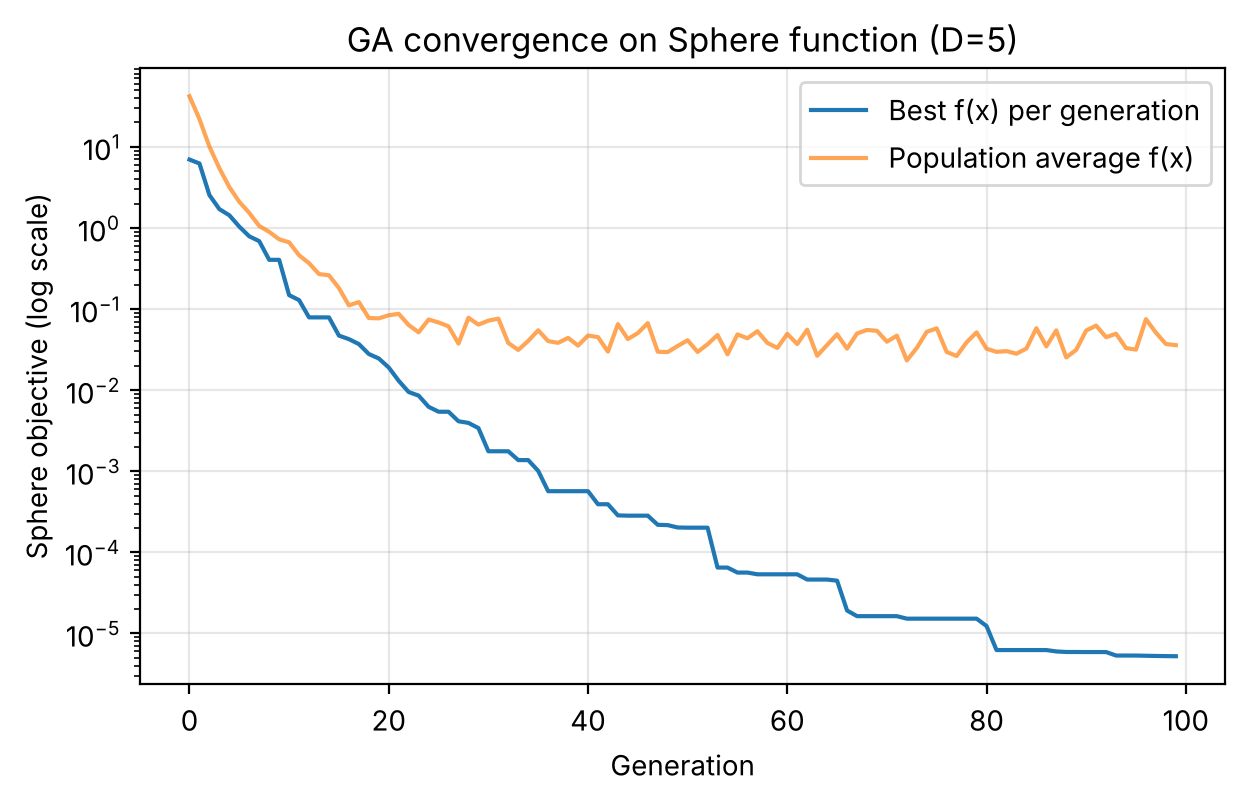

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(best_hist, label='Best f(x) per generation')
plt.plot(avg_hist, label='Population average f(x)', alpha=0.7)
plt.yscale('log')
plt.xlabel('Generation'); plt.ylabel('Sphere objective (log scale)')
plt.title('GA convergence on Sphere function (D=5)')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

### Observation
- The best objective value drops steadily over generations and approaches $0$, the known global minimum.
- The population average also falls, showing that the whole population moves toward the optimum.
- Elitism keeps the best value from increasing from one generation to the next.

### Conclusion
Built a complete real-coded GA from selection, crossover and mutation, and it found a solution very close to the optimum $\mathbf{x}=\mathbf{0}$.